<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/DSA211_07_Lab_Cross_Validation_Pipelines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part 0: Setup and Data

In this lab we,

- estimate test error with the validation-set approach, LOOCV, and k-fold CV.
- use stratified folds for classification and compare classifiers under CV.
- build leakage-free pipelines and see what happens without them.

We use three datasets.

1. `Auto` (regression: `mpg` vs `horsepower`) for Parts 1–3.
2. `Default` (classification, familiar from Week 5) for Part 4.
3. Part 5 uses simulated data where the truth is known exactly.

Full EDA is it is omitted for for brevity.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, LeaveOneOut, KFold, StratifiedKFold,
                                     cross_val_score, cross_validate, cross_val_predict)
from sklearn.metrics import mean_squared_error, confusion_matrix, RocCurveDisplay

In [ ]:
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Auto.csv'
Auto = pd.read_csv(url)
Auto.index = range(1, len(Auto) + 1)

print(Auto.shape)
print(Auto.isna().sum().sum(), 'missing values')
Auto.head()

(392, 9)
0 missing values


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
1,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
2,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
3,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
4,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
5,17.0,8,302.0,140,3449,10.5,70,1,ford torino


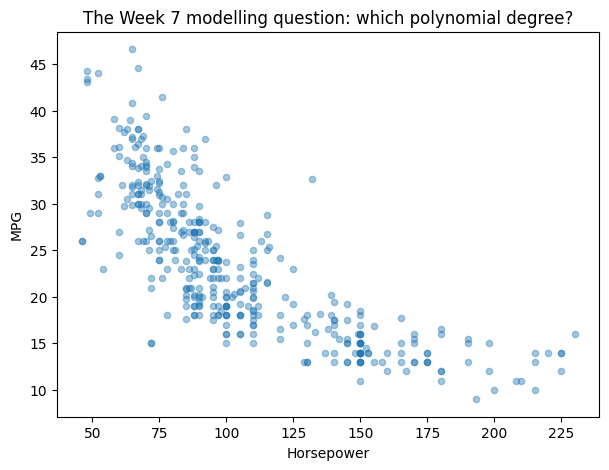

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Auto['horsepower'],
           Auto['mpg'],
           alpha=0.4,
           s=20)
ax.set_xlabel('Horsepower')
ax.set_ylabel('MPG')
ax.set_title('The Week 7 modelling question: which polynomial degree?')
plt.show()

In [ ]:
X = Auto[['horsepower']].values
y = Auto['mpg'].values

***

## Part 1: The Validation-Set Approach

Split once, fit on one set, evaluate on the other.

The demo below fits a linear model using an 80-20 split.

Note the two-step pattern: in sklearn we separate creating the model from fitting it, because cross-validation works by taking the *unfitted* object and fitting it once per fold.

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=2026)

model = LinearRegression()   # unfitted template
model.fit(X_train,
          y_train)

val_mse = mean_squared_error(y_val,
                             model.predict(X_val))
print(f'Validation MSE (linear fit): {val_mse:.2f}')

Validation MSE (linear fit): 23.87


### Exercise 1.1: Two split ratios, 100 splits each

Repeat the split-fit-evaluate cycle for 100 random splits (`random_state` = 0 to 99) at two split ratios, 80/20 (`test_size=0.2`) and 50/50 (`test_size=0.5`). For each ratio, report the mean and the standard deviation of the 100 validation MSEs.

In [ ]:
### YOUR CODE HERE
# 1. Loop over test_size in (0.2, 0.5)
# 2. Inside it, loop over seeds 0 to 99: split with random_state=seed, fit a linear
#    model on the training set, compute MSE on the validation set
# 3. For each test_size, print the mean and standard deviation of the 100 MSEs


for ts in (0.2, 0.5):
  mses = []
  for seed in range(100):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=ts, random_state=seed)
    model = LinearRegression().fit(X_train, y_train)   # unfitted template
    mses.append(mean_squared_error(y_val, model.predict(X_val)))
  print(f'test size={ts}: mean {np.mean(mses):.2f} SD {np.std(mses):.2f}')


test size=0.2: mean 23.94 SD 3.31
test size=0.5: mean 24.45 SD 2.05


❓ **Question 1.1.** Compare the two split ratios. What happened to the mean validation MSE, what happened to its standard deviation, and why do the two move in opposite directions?

*Your answer here:*

As the test size increase to 0.5 and have a more equal split ratios, the average MSEs increase to 24.45 from 23.94 whereas the standard deviation decrease to 2.05 from 3.31. This occurs because with a more equal split ratio, much of the training data is unused and rather used for testing. Hence, in attempt to avoid overfitting, higher test-ratio utilizes less training data which is opposite of lower test ratio. When the machine is trained on less data, there is higher bias which results in higher MSE.

Similar to MSE, the change in standard deviation is a result of the bias-variance tradeoff. Small validation are sensitive and make MSE fluctuate. With higher validation, larger sample sizes yield more consistent estimates (by law of large number).

***

## Part 2: Leave-One-Out Cross-Validation

LOOCV by brute force: 392 fits, one per observation.

`cross_val_score` generates the score using the unfitted model, a splitter, and a scoring rule.

In [ ]:
loo = LeaveOneOut()            # splitter: generates the n train/test index pairs
model = LinearRegression()     # unfitted template not fitted directly

# cross_val_score clones the template and fits one clone per split.
# sklearn scorers follow a 'higher is better' convention, so MSE enters as a negative.
loo_scores = cross_val_score(model, X, y, cv=loo, scoring='neg_mean_squared_error')
print(f'LOOCV MSE (brute force, {len(loo_scores)} fits): {-loo_scores.mean():.4f}')

LOOCV MSE (brute force, 392 fits): 24.2315


> **Scoring strings.** `scoring=` takes a name from `sklearn.metrics.get_scorer_names()`. sklearn treats higher as better, so error metrics come negated (`'neg_mean_squared_error'`, `'neg_root_mean_squared_error'`, `'neg_mean_absolute_error'`) and you flip the sign when reporting. `'r2'` is already higher-is-better, so it has no `neg_`.

### Exercise 2.1: The LOOCV shortcut

For OLS, one fit gives the exact LOOCV error:

$$\text{CV}_{(n)} = \frac{1}{n} \sum_{i=1}^{n} \left( \frac{y_i - \hat{y}_i}{1 - h_{ii}} \right)^2 .$$

Fit the linear model once with statsmodels, take the leverages $h_{ii}$ from `get_influence().hat_matrix_diag` (Week 4), and compute the shortcut. Print it next to the brute-force value above.

In [ ]:
### YOUR CODE HERE
# 1. Fit sm.OLS(y, sm.add_constant(X))
# 2. h = the leverages, from .get_influence().hat_matrix_diag
# 3. Compute the mean of ((y - fitted values) / (1 - h))**2
# 4. Print it next to -loo_scores.mean()

loo = LeaveOneOut()
model = LinearRegression()
loo_scores = cross_val_score(model,
                             X,
                             y,
                             cv=loo,
                             scoring='neg_mean_squared_error')

linear = sm.OLS(y, sm.add_constant(X)).fit()
h = linear.get_influence().hat_matrix_diag
CV = np.mean(((y - linear.fittedvalues) / (1 - h))**2)

print(f'LOOCV MSE bruteforce: {-loo_scores.mean():.4f} , LOOCV MSE shortcut: {CV:.4f}')



LOOCV MSE bruteforce: 24.2315 , LOOCV MSE shortcut: 24.2315


❓ **Question 2.1.** The shortcut needed one fit; brute force needed 392. Would the same shortcut give the LOOCV error of the logistic regression in Part 4? Why or why not?

*Your answer here:*

I honestly don't think so because the shortcut requires fitting an OLS linear model to utilize the hat matrix; however a logistic regression is shouldn't be fitted with an OLS linear model as the values between the two category of the fitted linear line is misleading. Hence, the hat matrix **from OLS** is incompatible for logistic regression. As a result, the shortcut method which utilizes the hat matrix would be misleading.

***

## Part 3: k-Fold CV for Model Choice

### 3.1 k-Fold CV with MSE as the Scoring

The workhorse. We choose the polynomial degree by 10-fold CV, as in the lecture.

Each degree is a short pipeline, `poly_pipe`: standardise `horsepower`, take its powers, then fit OLS. We build it once and change the degree with `poly_pipe.set_params(poly__degree=d)`: the step name, two underscores, then the parameter. Standardising first keeps the powers on a sensible scale. Raw `horsepower` reaches about $10^{23}$ at the tenth power, and recent versions of `sklearn` (1.9 onwards) then return inaccurate fits from degree 3.

In [ ]:
poly_pipe = Pipeline([('scale', StandardScaler()),
                      ('poly',  PolynomialFeatures(include_bias=False)),
                      ('ols',   LinearRegression())])

degrees = range(1, 11)
kf = KFold(n_splits=10, shuffle=True, random_state=2026)

cv_mse = []
# change the polynomial degree with set_params: step name + __ + parameter
# e.g. poly_pipe.set_params(poly__degree=3)
for d in degrees:
    poly_pipe.set_params(poly__degree=d)
    scores = cross_val_score(poly_pipe,
                             X,
                             y,
                             cv=kf,
                             scoring='neg_mean_squared_error')
    cv_mse.append(-scores.mean())

results = pd.DataFrame({'degree': degrees,
                        'cv_mse_k10': np.round(cv_mse, 2)})
print(results.to_string(index=False))

 degree  cv_mse_k10
      1       24.15
      2       19.27
      3       19.47
      4       19.90
      5       19.70
      6       19.53
      7       19.29
      8       19.52
      9       19.93
     10       20.33


### Exercise 3.1: 5-fold versus 10-fold

Repeat the degree search with **5-fold** CV (same `shuffle=True, random_state=2026`). Add the results as a new column `cv_mse_k5` and plot both curves against degree on the same axes.

 degree  cv_mse_k5  cv_mse_k10
      1      24.12       24.15
      2      19.48       19.27
      3      19.74       19.47
      4      19.91       19.90
      5      19.71       19.70
      6      19.48       19.53
      7      19.22       19.29
      8      19.68       19.52
      9      20.18       19.93
     10      20.68       20.33


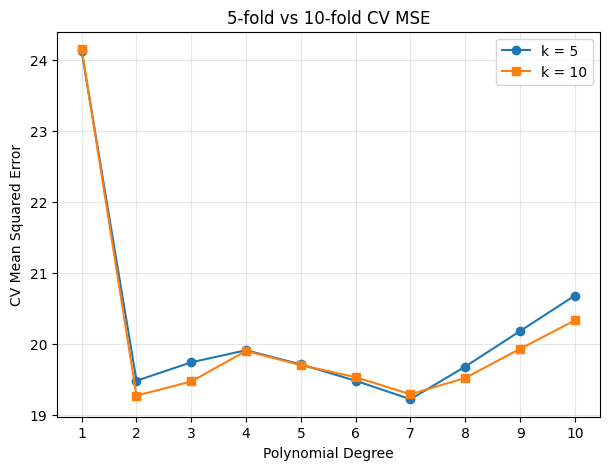

In [ ]:
### YOUR CODE HERE
# 1. Create a KFold splitter with n_splits=5
# 2. Re-run the degree loop and collect the 5-fold CV MSEs
# 3. Plot both curves (k=10 and k=5) with labels and a legend
# 4. Remember plt.show()

poly_pipe = Pipeline([('scale', StandardScaler()),
                      ('poly',  PolynomialFeatures(include_bias=False)),
                      ('ols',   LinearRegression())])

degrees = range(1, 11)
cv_results = {'degree': list(degrees)}

for s in (5, 10):
  kf = KFold(n_splits=s, shuffle=True, random_state=2026)
  cv_mse = []
  for d in degrees:
    poly_pipe.set_params(poly__degree=d)
    scores = cross_val_score(poly_pipe,
                             X,
                             y,
                             cv=kf,
                             scoring='neg_mean_squared_error')
    cv_mse.append(-scores.mean())

  cv_results[f"cv_mse_k{s}"] = np.round(cv_mse, 2)

results = pd.DataFrame(cv_results)
print(results.to_string(index=False))

plt.figure(figsize=(7, 5))
plt.plot(degrees, results['cv_mse_k5'], 'o-', label='k = 5')
plt.plot(degrees, results['cv_mse_k10'], 's-', label='k = 10')
plt.xlabel('Polynomial Degree')
plt.ylabel('CV Mean Squared Error')
plt.title('5-fold vs 10-fold CV MSE')
plt.xticks(degrees)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

❓ **Question 3.1a.** Which degree would you choose, and why? Your answer should refer to the shape of the CV curve, not just its minimum.



*Your answer here:*

I would choose degree number 2 because of its simplicity compared to degree number 7 that provides the around the same MSE. When we increase to degree 4 or 5, we see that the model is overfitting.

❓ **Question 3.1b.** The k=5 and k=10 curves are close but not identical. Using the bias–variance trade-off *inside CV itself*, which estimate do you expect to be slightly more pessimistic (biased upward), and why?

*Your answer here:*

I epect that the model with 5 folds is slightly more pessimistic because at polynomial degree 1, 5-fold model has higher MSE, perhaps from higher bias.

### 3.2 k-Fold CV with $R^2$ as the Scoring

In the demonstration below, we change the scoring system to the $R^2$ value.

In [ ]:
# R-sq is a scoring string too: higher is better, so no neg_
for d in degrees:
    poly_pipe.set_params(poly__degree=d)
    r2 = cross_val_score(poly_pipe,
                         X,
                         y,
                         cv=kf,
                         scoring='r2')
    print(f'Degree {d}: 10-fold CV R² = {r2.mean():.3f}')

Degree 1: 10-fold CV R² = 0.595
Degree 2: 10-fold CV R² = 0.679
Degree 3: 10-fold CV R² = 0.677
Degree 4: 10-fold CV R² = 0.670
Degree 5: 10-fold CV R² = 0.674
Degree 6: 10-fold CV R² = 0.676
Degree 7: 10-fold CV R² = 0.680
Degree 8: 10-fold CV R² = 0.677
Degree 9: 10-fold CV R² = 0.672
Degree 10: 10-fold CV R² = 0.666


### Exercise 3.2: MSE and R² in one call

`cross_val_score` takes one scoring string. `cross_validate` on the other hand, takes a list and returns one `test_<name>` array per scorer. With `return_train_score=True` it also returns the matching `train_<name>` arrays, scored on the training folds.

For the degree-2 model, use `cross_validate` with the same `kf` splitter to get the 10-fold CV MSE and CV $R^2$ in one call, together with the training $R^2$.

In [ ]:
### YOUR CODE HERE
# 1. Set poly_pipe from 3.1 to degree 2 with set_params(poly__degree=2)
# 2. cross_validate(poly_pipe, X, y, cv=kf,
#                   scoring=['neg_mean_squared_error', 'r2'], return_train_score=True)
# 3. Print the mean test MSE (flip the sign), the mean test R², and the mean train R²

poly_pipe = Pipeline([('scale', StandardScaler()),
                      ('poly',  PolynomialFeatures(include_bias=False)),
                      ('ols',   LinearRegression())])

kf = KFold(n_splits=10, shuffle=True, random_state=2026)
cv_mse = []

poly_pipe.set_params(poly__degree=2)
r2 = cross_validate(poly_pipe, X, y, cv=kf,
                   scoring=['neg_mean_squared_error', 'r2'], return_train_score=True)

mean_test_mse = -r2['test_neg_mean_squared_error'].mean()
mean_test_r2 = r2['test_r2'].mean()
mean_train_r2 = r2['train_r2'].mean()

results = pd.DataFrame({
    'Mean test MSE' :  mean_test_mse,
    'Mean test R^2' :  mean_test_r2,
    'Mean train R^2' :  mean_train_r2,
}, index=[0])

print(results.to_string(index=False))
print(f"\nThe mean test MSE is {mean_test_mse:.3f} and test R^2 is {mean_test_r2:.3f}. The mean train R^2 is {mean_train_r2:.3f}")

 Mean test MSE  Mean test R^2  Mean train R^2
     19.272107       0.678538        0.687756

The mean test MSE is 19.272 and test R^2 is 0.679. The mean train R^2 is 0.688


❓ **Question 3.2.** Interpret the CV R² for degree 2 in one sentence. Why is it lower than the training R², and why is the gap small here?

*Your answer here:*

1. Interpretation: Under 10 fold cross validation, approximately 0.679 of the total variance is explained by the degree-2 polynomial model of horsepower.

2. I think that the test R^2 is lower than the training R^2 because the modek was built upon the trained data. It is natural that the model performs better when testing with "training data" than to test with another dataset like "test data".

3. Perhaps the gap is small because the model is relavtively simple with 2 polynomial degrees and 3 parameters (B0 + B1X + B1X^2); hence, the model doesn't struggle with overfitting.

***

## Part 4: Cross-Validation for Classification

We switch to the `Default` dataset from Week 5: 10,000 customers, 3.3% default rate. Classification brings two complications that regression did not have: the choice of error metric, and the composition of the folds. Both are consequences of imbalance.

In [ ]:
url_default = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Default.csv'
Default = pd.read_csv(url_default)
Default.index = range(1, len(Default) + 1)

X_def = pd.get_dummies(Default[['student', 'balance', 'income']], drop_first=True).astype(float)
y_def = (Default['default'] == 'Yes').astype(int).values

print(X_def.columns.tolist())
print(f'n = {len(y_def)}, base rate = {y_def.mean():.3f}')

['balance', 'income', 'student_Yes']
n = 10000, base rate = 0.033


### 4.1 Evaluating a Classifier Under Imbalance

In the `Default` data, the 3.3% base rate makes accuracy a poor choice for model evaluation (Lecture 5). A classifier that predicts "no default" for everyone scores 96.7%. Basically, accuracy restates the base rate.

A good evaluation reports the Week 5 metrics side by side: accuracy, AUC (threshold-free discrimination), and sensitivity (the fraction of defaulters caught). The demo computes all three under stratified 10-fold CV, using our standard pattern:

1. Preprocessing and estimator chained into one pipeline,
2. Re-fit inside every training fold.

Scaling barely changes logistic regression. However, we still include it in the pipeline because it is a textbook example of a step that learns from the data (one mean and an SD per column). We return to this when we discuss penalised regressions in Lecture 9.

In [ ]:
pipe_lr = Pipeline([
    ('scale', StandardScaler()),
    ('clf',   LogisticRegression())
])

skf = StratifiedKFold(n_splits=10,
                      shuffle=True,
                      random_state=2026)
res = cross_validate(pipe_lr,
                     X_def,
                     y_def,
                     cv=skf,
                     scoring=['accuracy', 'roc_auc', 'recall'])

print(f"Accuracy:             {res['test_accuracy'].mean():.3f}")
print(f"AUC:                  {res['test_roc_auc'].mean():.3f}")
print(f"Sensitivity (recall): {res['test_recall'].mean():.3f}")

Accuracy:             0.973
AUC:                  0.950
Sensitivity (recall): 0.316


**Why the Folds Must Be Stratified**

The demo used `StratifiedKFold`, which forces every fold to match the full-sample class proportions. At n = 10,000, each of ten folds expects about 33 defaulters. Shrink the sample and the arithmetic turns against you: a subsample of 200 customers is expected to contain about 7 defaulters, so each of 5 folds expects fewer than 2, and random folding can easily leave a fold with none. A fold with no positives says nothing about the model's ability to catch defaults, and sensitivity and AUC become *undefined*. Lecture 7, Section 7 shows this on a 200-customer subsample.

### 4.2 Comparing Classifiers Under Cross-Validation

Here we compare logistic regression with generative classifiers under k-fold CV, using AUC and a confusion matrix. `cross_validate` gives fold-averaged scores. A confusion matrix or an ROC curve needs one prediction per customer. `cross_val_predict` gives a prediction for every customer, each made by the model that did not train on them. These are called **out-of-fold** predictions.

The demo uses the `skf` splitter from 4.1 throughout. It first runs `cross_validate` for logistic regression, LDA and Naive Bayes and collects the mean accuracy, AUC and sensitivity into one table. It then uses `cross_val_predict(..., method='predict_proba')` to get out-of-fold probabilities, overlays the three ROC curves, and prints each confusion matrix at the 0.5 threshold. LDA and Naive Bayes need no scaler: rescaling a predictor does not change their predictions.

In [ ]:
# Define the model and metrics
models = {'Logistic':    pipe_lr,
          'LDA':         LinearDiscriminantAnalysis(),
          'Naive Bayes': GaussianNB()}
metrics = ['accuracy', 'roc_auc', 'recall']

# Fold-averaged scores, one row per model
table = pd.DataFrame({name: {m: cross_validate(model,
                                               X_def,
                                               y_def,
                                               cv=skf,
                                               scoring=metrics)[f'test_{m}'].mean()
                             for m in metrics}
                      for name, model in models.items()}).T
print(table.round(3), '\n')

             accuracy  roc_auc  recall
Logistic        0.973    0.950   0.316
LDA             0.973    0.950   0.243
Naive Bayes     0.970    0.945   0.255 



Logistic (rows = actual, cols = predicted)
[[9628   39]
 [ 228  105]]

LDA (rows = actual, cols = predicted)
[[9644   23]
 [ 252   81]]

Naive Bayes (rows = actual, cols = predicted)
[[9620   47]
 [ 248   85]]



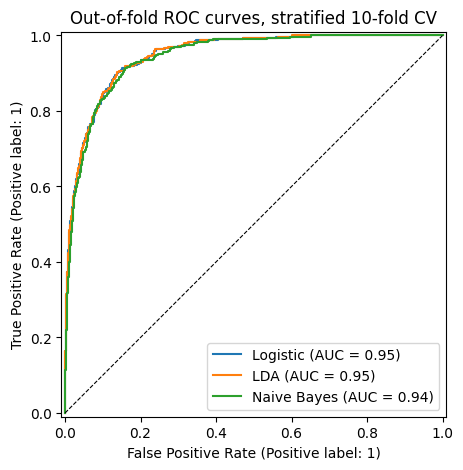

In [ ]:
# out-of-fold probabilities: one prediction per customer, kept in oof
oof = {}
fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    oof[name] = prob = cross_val_predict(model,
                                         X_def,
                                         y_def,
                                         cv=skf,
                                         method='predict_proba')[:, 1]
    RocCurveDisplay.from_predictions(y_def,
                                     prob,
                                     name=name,
                                     ax=ax)
    print(f'{name} (rows = actual, cols = predicted)\n{confusion_matrix(y_def, (prob >= 0.5).astype(int))}\n')
ax.plot([0, 1],
        [0, 1],
        'k--',
        linewidth=0.8)
ax.set_title('Out-of-fold ROC curves, stratified 10-fold CV')
plt.show()

### Exercise 4.2: Logistic regression at a lower threshold

The demo kept each model's out-of-fold probabilities in the dictionary `oof`. Classify the logistic regression probabilities at a threshold of 0.2 instead of 0.5. Print the confusion matrix, then the sensitivity, specificity and accuracy, and compare them with the 0.5 results above.

In [ ]:
### YOUR CODE HERE
# 1. pred = (oof['Logistic'] >= 0.2).astype(int)
# 2. cm = confusion_matrix(y_def, pred); tn, fp, fn, tp = cm.ravel()
# 3. Print cm, then sensitivity, specificity and accuracy
for model in ('Logistic', 'LDA', 'Naive Bayes'):
  pred = (oof[model] >= 0.2).astype(int)
  cm = confusion_matrix(y_def, pred); tn, fp, fn, tp = cm.ravel()

  sensitivity = tp/(fn+tp)
  specificity = tn/(fp+tn)
  accuracy = (tp+tn)/10000

  table = pd.DataFrame({
      'Sensitivity' : sensitivity,
      'Specificity' : specificity,
      'Accuracy' : accuracy,
  },index=[0])
  print()
  print(f"The confusion matrix of the {model} classifier is \n {cm}")
  print(table.to_string(index=False))



The confusion matrix of the Logistic classifier is 
 [[9394  273]
 [ 132  201]]
 Sensitivity  Specificity  Accuracy
    0.603604      0.97176    0.9595

The confusion matrix of the LDA classifier is 
 [[9432  235]
 [ 140  193]]
 Sensitivity  Specificity  Accuracy
     0.57958      0.97569    0.9625

The confusion matrix of the Naive Bayes classifier is 
 [[9340  327]
 [ 128  205]]
 Sensitivity  Specificity  Accuracy
    0.615616     0.966174    0.9545


❓ **Question 4.2.** Which classifier would you choose for `Default`, and on what evidence? Why is sensitivity so much lower than accuracy for all three?

*Your answer here:*

I believe that it's more costly to miss a defaulter than it is to mis-flag someone as a non-defaulter, hence, I would choose classifer Naive Bayes because it has the highest sensitivity and has the highest chance of correctly identifying a true defaulter. (0.615616 > 0.603604 > 0.57958)

Sensitivity is much lower than accuracy because the dataset is imbalanced. Accuracy accounts for both the probability of correctly identifying true positives and true negatives. Because the "Default" dataset is imblanced towards more negatives, Specificity is "carrying" the high accuracy.

***

## Part 5: Data Leakage: Seeing It, Then Fixing It

The lecture showed labels leaking into a feature's *values* through target encoding.

Here you will produce the other doorway: labels (the class of Y) leaking into the feature *choice*.

Once again we consider a setup where the answer is known: $n = 50$ observations, $p = 1000$ predictors of pure noise, labels assigned by coin flip. No learning method can beat 50% accuracy.

A common high-dimensional workflow:

- screen the predictors first

- keep the $k$ predictors most associated with the outcome

- then cross-validate a model on the survivors.

`SelectKBest(f_classif, k=20)` scores each predictor by a one-way ANOVA F-test against the labels and keeps the top 20.

We will run it the wrong way first:

In [ ]:
rng = np.random.default_rng(2026)
n, p = 50, 1000
X_noise = rng.standard_normal((n, p))
y_noise = rng.permutation(np.repeat([0, 1], n // 2))   # exactly 50/50: nothing to learn

# THE WRONG WAY: select features on the FULL dataset, then cross-validate
selector = SelectKBest(f_classif, k=20) # ANOVA feature selector
selector.fit(X_noise, y_noise)
X_selected = selector.transform(X_noise)

skf_small = StratifiedKFold(n_splits=5,
                            shuffle=True,
                            random_state=2026)
leaky_acc = cross_val_score(LogisticRegression(),
                            X_selected,
                            y_noise,
                            cv=skf_small).mean()
print(f'CV accuracy with leakage: {leaky_acc:.2f}   (truth: 0.50)')

CV accuracy with leakage: 0.94   (truth: 0.50)


❓ **Question 5.1a.** Explain the mechanism in your own words. Why does running 1000 F-tests on 50 observations *guarantee* some strong spurious associations, and why does selecting the winners contaminate every future held-out fold? (Hint: this is the Week 3 multiple-testing problem in a new costume.)

*Your answer here:*

In week 3, the multiple-testing problem states that the more predictors you have, the more likely to have 1 or more false rejection simply by chance alone.

In this context, by running 1000 F-tests on few observations (50), it is likely that some of these predictors, by chance alone, appear as if they relate to the labels.

### Exercise 5.1: Move the selection inside the pipeline

Build a `Pipeline` with the `SelectKBest` step and the logistic regression chained together, and re-run `cross_val_score` on the *raw* `X_noise`. The selection now happens inside each training fold.

In [ ]:
### YOUR CODE HERE
# 1. Pipeline with steps ('select', SelectKBest(f_classif, k=20))
#    and ('clf', LogisticRegression())
# 2. cross_val_score on X_noise (NOT X_selected), same skf_small splitter
# 3. Print the honest CV accuracy

honest_pipeline = Pipeline([
    ('select', SelectKBest(f_classif, k=20)),
    ('clf', LogisticRegression())
])

honest_acc = cross_val_score(honest_pipeline,
                             X_noise,
                             y_noise,
                             cv=skf_small).mean()

print(f'Honest CV accuracy: {honest_acc:.2f}   (truth: 0.50)')


Honest CV accuracy: 0.34   (truth: 0.50)


❓ **Question 5.1b.** Same data, same model, same folds. Only *where the selection step learns* changed. State the general rule, and classify each of the following as inside-the-fold or safe-outside: (a) taking the log of a predictor; (b) standardising with sample mean and SD; (c) mean-imputing missing values; (d) creating a dummy from a fixed, pre-defined category list.

*Your answer here:*

The general rule is that steps that allow the model to learn the slightest, is disallowed to avoid leakage.

a: safe-outside

b: inside-the-fold

c: inside-the-fold

d: safe-outside

***

## Checklist

Before submitting, confirm you can:

- [ ] Exercise 1.1, Question 1.1: run the validation-set approach at two split ratios and explain its two costs
- [ ] Exercise 2.1, Question 2.1: compute LOOCV by brute force and by the leverage shortcut, and say when the shortcut applies
- [ ] Exercise 3.1, Questions 3.1a–b: choose a polynomial degree with k-fold CV and defend the choice from the shape of the curve
- [ ] Exercise 3.2, Question 3.2: score with several metrics at once using `cross_validate`, and explain why CV R² is below training R²
- [ ] Exercise 4.2, Question 4.2: compare classifiers under CV, use out-of-fold predictions from `cross_val_predict`, and change the classification threshold
- [ ] Question 5.1a, Exercise 5.1, Question 5.1b: explain the leakage mechanism, build a leakage-free `Pipeline`, and state the rule for what belongs inside it